# Survival After Pediatric Hematopoietic Stem Cell Transplantation
### The Role of Stem-Cell Source and CD34+ Cell Dose
**Module:** Data Science in Health Care — MSc Applied Data Science and AI, HSLU
**Group 1:** Ibtihel Frini, Yasna Ahmad, Paula Barghout

> **Version 3 changelog (relative to DSHC_V2).**
> - Added a *Background and motivation* section (feedback: explain HSCT and CD34+ before the analysis).
> - Hypotheses now state the exact test, statistic and decision threshold (feedback).
> - Missing-data handling is now specified concretely (feedback on §2.1).
> - Added the steps planned in the preliminary study that were missing from V2: overall Kaplan–Meier curve, CD34+ dose by stem-cell source, the nested Cox Models 1 → 2 → 3, the formal H1 attenuation test, the Random Survival Forest, and the secondary engraftment analysis.
> - **Correction:** recipient age is now *centred* before squaring. In V2 the linear age term of the quadratic model (HR 0.843) was the effect at age 0, which is not interpretable and is strongly collinear with age². The model fit is identical; only the parameterisation changes.
> - Added a data-integrity check of the `1,000,000` placeholder values and of event-time ordering.

## 1. Background and motivation

**Hematopoietic stem cell transplantation (HSCT)** replaces a patient's diseased or destroyed blood-forming system with healthy *hematopoietic stem cells* from a donor. It is a potentially curative treatment for childhood leukaemias (ALL, AML, chronic leukaemias), lymphomas, and non-malignant disorders such as severe aplastic anaemia or Fanconi anaemia. All patients in this dataset received an **allogeneic, unrelated-donor** transplant: the cells come from a matched volunteer, not from the patient or a sibling.

HSCT remains high-risk: transplant-related complications (infection, graft-versus-host disease, graft failure) and relapse mean that a substantial share of children do not survive long-term. In this cohort, **85 of 187 children (45%) died during follow-up**. Identifying which *modifiable* transplant decisions are associated with survival is therefore clinically important.

Two such decisions are studied here:

- **Stem-cell source.** Donor stem cells can be harvested directly from the **bone marrow (BM)**, or collected from **peripheral blood (PB)** after the donor is given growth-factor injections that mobilise stem cells into the bloodstream.
- **CD34+ cell dose.** **CD34** is a surface protein that marks hematopoietic stem and progenitor cells. The number of CD34+ cells infused per kg of the child's body weight (here ×10⁶/kg) is the standard measure of *how much graft* the child receives. Higher doses are linked to faster engraftment (recovery of blood counts).

**Why the two must be studied together.** PB grafts typically contain *many more* CD34+ cells than BM grafts. If PB recipients appear to survive longer, it is unclear whether that reflects the *source* itself or simply the *larger cell dose* that comes with it. Our research question separates these two explanations.

The dataset's own documentation states that the original study aimed to verify *"that increased dosage of CD34+ cells/kg extends overall survival time without simultaneous occurrence of undesirable events"* (Sikora & Wróbel, UCI repository).

## 2. Research question and hypotheses

**Main question.** Is the source of hematopoietic stem cells associated with overall survival in pediatric transplant patients, and does this association remain after accounting for CD34+ cell dose and selected clinical factors?

**Outcome.** Overall survival: `survival_time` (days) with event indicator `survival_status` (1 = death, 0 = alive/censored).

All tests are two-sided with significance level **α = 0.05**. Effects are reported as hazard ratios (HR) with 95% confidence intervals; HR < 1 means a lower hazard of death.

| | Hypothesis | Test and statistic | Decision rule |
|---|---|---|---|
| **H1a** | Stem-cell source is associated with overall survival (unadjusted). | Log-rank test (χ², 1 df) on the Kaplan–Meier curves; Wald test of β<sub>source</sub> in Cox Model 1. | Association if p < 0.05. |
| **H1b** | The source association **weakens** after adjustment for CD34+ dose. | Change-in-estimate: % change in β<sub>source</sub> (log-HR) from Model 1 to Model 2, with a 1,000-resample bootstrap 95% CI for the difference β<sub>M1</sub> − β<sub>M2</sub>. | Meaningful attenuation if the change is ≥ 10% *and* the bootstrap CI for the difference excludes 0. |
| **H2** | A higher CD34+ dose is associated with longer survival after adjustment for patient and transplant characteristics. | Wald test of β<sub>CD34</sub> in the adjusted Cox model (Model 3), H₀: HR = 1. | Supported if HR < 1 and p < 0.05. |

**Secondary outcome.** Time to neutrophil (ANC) and platelet recovery (engraftment), analysed with competing-risks methods (§13).

## 3. Objectives

1. Describe the study population and assess the completeness and quality of the data.
2. Examine overall survival using Kaplan–Meier estimates.
3. Compare survival between patients receiving bone marrow and peripheral blood stem cells.
4. Investigate the association between CD34+ cell dose and overall survival, and how CD34+ dose differs by stem-cell source.
5. Fit a sequence of parsimonious Cox proportional-hazards models to assess whether the source association persists after adjustment.
6. Complement the statistical model with a Random Survival Forest evaluated by cross-validated, survival-specific metrics.
7. Evaluate model assumptions and discuss the limitations of the findings.

## 4. Dataset

The analysis uses the *Bone Marrow Transplant: Children* dataset (UCI Machine Learning Repository), containing 187 pediatric patients and 37 attributes. All patients underwent unmanipulated allogeneic unrelated-donor HSCT for malignant (ALL, AML, chronic leukaemia, lymphoma) or non-malignant disorders.

## 5. Analytical approach

The analysis begins with data validation and descriptive statistics. Survival methods are used only after confirming the interpretation of the survival time and event indicator. Model complexity is limited in line with the number of observed events (85 deaths; we keep the final Cox model at ≤ 9 parameters, i.e. ≈ 9–10 events per parameter).

**Missing-data strategy (specified).**
- *Cox models:* every variable used (survival time/status, stem-cell source, CD34+ dose, recipient age, risk group, disease) is **complete**, so the Cox models use all 187 patients and no imputation is needed.
- *Random Survival Forest:* the wider pre-transplant feature set has a few gaps (max. 8.6%, `CMVstatus`). These are imputed with the **median** (numeric) or **most frequent value** (categorical/ordinal) using scikit-learn's `SimpleImputer`, placed **inside the modelling pipeline** so that it is re-fitted on the training folds only and never sees the test fold (no information leakage).
- *Post-transplant variables* (`extcGvHD`, the variable with most missingness, plus relapse, acute GvHD, recovery times) are **excluded** from the predictive models because they occur after transplantation and would leak outcome information.
- *Placeholder values:* `1,000,000` in `ANCrecovery`, `PLTrecovery` and `time_to_aGvHD_III_IV` means "event not observed" and is converted to censoring / competing events, never used as a time.

The results are interpreted as observational associations, not causal effects.

## 6. Setup and data loading

In [1]:
# Data handling
import numpy as np
import pandas as pd
import warnings

# Loading the ARFF dataset
from scipy.io import arff
from scipy.stats import chi2, mannwhitneyu, spearmanr

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Survival analysis
from lifelines import KaplanMeierFitter, CoxPHFitter, AalenJohansenFitter
from lifelines.statistics import logrank_test, proportional_hazard_test
from lifelines.plotting import add_at_risk_counts

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Load the ARFF dataset
raw_data, metadata = arff.loadarff("bone-marrow.arff")
df = pd.DataFrame(raw_data)

# Decode byte strings into regular strings
for column in df.select_dtypes(include="object").columns:
    df[column] = df[column].apply(
        lambda value: value.decode("utf-8") if isinstance(value, bytes) else value
    )

# Replace '?' placeholders with missing values
df = df.replace("?", np.nan)

print("Dataset loaded successfully.")
print(f"Number of patients: {df.shape[0]}")
print(f"Number of attributes: {df.shape[1]}")

Dataset loaded successfully.
Number of patients: 187
Number of attributes: 37


## 7. Data quality

In [3]:
# Inspect the first five records
display(df.head())

# Inspect column names and data types
print("\nDataset information:")
df.info()

# Check duplicate records
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Count missing values
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": df.isna().mean() * 100,
})
missing_summary = missing_summary[missing_summary["Missing_Count"] > 0].sort_values(
    "Missing_Percentage", ascending=False
)
print("\nMissing-value summary:")
display(missing_summary)

,Recipientgender,Stemcellsource,Donorage,Donorage35,IIIV,Gendermatch,DonorABO,RecipientABO,RecipientRh,ABOmatch,CMVstatus,DonorCMV,RecipientCMV,Disease,Riskgroup,Txpostrelapse,Diseasegroup,HLAmatch,HLAmismatch,Antigen,Alel,HLAgrI,Recipientage,Recipientage10,Recipientageint,Relapse,aGvHDIIIIV,extcGvHD,CD34kgx10d6,CD3dCD34,CD3dkgx10d8,Rbodymass,ANCrecovery,PLTrecovery,time_to_aGvHD_III_IV,survival_time,survival_status
0,1,1,22.830,0,1,0,1,1,1,0,3,1,1,ALL,1,0,1,0,0,-1,-1,0,9.600,0,1,0,0,1,7.200,1.339,5.380,35.000,19.000,51.000,32.000,999.000,0.000
1,1,0,23.342,0,1,0,-1,-1,1,0,0,0,0,ALL,0,0,1,0,0,-1,-1,0,4.000,0,0,1,1,1,4.500,11.078,0.410,20.600,16.000,37.000,1000000.000,163.000,1.000
2,1,0,26.395,0,1,0,-1,-1,1,0,2,0,1,ALL,0,0,1,0,0,-1,-1,0,6.600,0,1,1,1,1,7.940,19.013,0.420,23.400,23.000,20.000,1000000.000,435.000,1.000
3,0,0,39.685,1,1,0,1,2,1,1,1,1,0,AML,0,0,1,0,0,-1,-1,0,18.100,1,2,0,0,NaN,4.250,29.482,0.140,50.000,23.000,29.000,19.000,53.000,1.000
4,0,1,33.359,0,0,0,1,2,0,1,0,0,1,chronic,1,0,1,1,0,1,0,1,1.300,0,0,0,1,1,51.850,3.972,13.050,9.000,14.000,14.000,1000000.000,2043.000,0.000



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 187 entries, 0 to 186
Data columns (total 37 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Recipientgender       187 non-null    object 
 1   Stemcellsource        187 non-null    object 
 2   Donorage              187 non-null    float64
 3   Donorage35            187 non-null    object 
 4   IIIV                  187 non-null    object 
 5   Gendermatch           187 non-null    object 
 6   DonorABO              187 non-null    object 
 7   RecipientABO          186 non-null    object 
 8   RecipientRh           185 non-null    object 
 9   ABOmatch              186 non-null    object 
 10  CMVstatus             171 non-null    object 
 11  DonorCMV              185 non-null    object 
 12  RecipientCMV          173 non-null    object 
 13  Disease               187 non-null    object 
 14  Riskgroup             187 non-null    object 
 15  T

,Missing_Count,Missing_Percentage
extcGvHD,31,16.578
CMVstatus,16,8.556
RecipientCMV,14,7.487
CD3dCD34,5,2.674
CD3dkgx10d8,5,2.674
DonorCMV,2,1.070
RecipientRh,2,1.070
Rbodymass,2,1.070
ABOmatch,1,0.535
RecipientABO,1,0.535


### 7.1 Placeholder values and event-time consistency (new)
The value `1,000,000` in the recovery / GvHD time variables is a placeholder for "event not observed", not a real time. We count these placeholders, check who they belong to, and check that no observed event time falls *after* the patient's death or last follow-up.

In [4]:
SENTINEL = 1_000_000
time_vars = ["ANCrecovery", "PLTrecovery", "time_to_aGvHD_III_IV"]

integrity = []
for v in time_vars:
    not_observed = df[v] >= SENTINEL
    observed = ~not_observed
    integrity.append({
        "variable": v,
        "placeholder (not observed)": int(not_observed.sum()),
        "...of whom died": int((not_observed & (df["survival_status"] == 1)).sum()),
        "observed time > survival_time": int((observed & (df[v] > df["survival_time"])).sum()),
    })
display(pd.DataFrame(integrity).set_index("variable"))

print("Records where platelet recovery is recorded after death / last follow-up:")
display(df.loc[(df["PLTrecovery"] < SENTINEL) & (df["PLTrecovery"] > df["survival_time"]),
               ["ANCrecovery", "PLTrecovery", "survival_time", "survival_status"]])

,placeholder (not observed),...of whom died,observed time > survival_time
variable,,,
ANCrecovery,5,5,0
PLTrecovery,17,17,2
time_to_aGvHD_III_IV,145,62,0


Records where platelet recovery is recorded after death / last follow-up:


,ANCrecovery,PLTrecovery,survival_time,survival_status
7,22.000,58.000,45.000,1.000
63,18.000,30.000,19.000,1.000


**Findings.** All 5 patients without neutrophil recovery and all 17 without platelet recovery **died** before recovering. Graft failure and early death are therefore intertwined, which is why the engraftment analysis (§13) treats death as a *competing event* rather than simple censoring. Two records list platelet recovery *after* the recorded death (e.g. recovery on day 58, death on day 45). These are impossible and are treated as "platelet recovery not observed before death" in §13. They do not affect the overall-survival analysis.

## 8. Validation of survival variables
The dataset documentation defines `survival_time` as the observation time for patients who were alive or the time to event for patients who died, measured in days. `survival_status` indicates whether the patient was alive (0) or dead (1) at the end of the recorded observation period, so it can be used as the event indicator.

The main explanatory variable, `Stemcellsource`, identifies the stem-cell source: bone marrow (0) or peripheral blood (1).

In [5]:
print("Survival time summary:")
display(df["survival_time"].describe())

print("\nSurvival status counts (0 = alive/censored, 1 = death):")
display(df["survival_status"].value_counts(dropna=False).sort_index())
display(df["survival_status"].value_counts(normalize=True).sort_index())

print("\nNumber of non-positive survival times:", (df["survival_time"] <= 0).sum())
print("Missing survival times:", df["survival_time"].isna().sum())
print("Missing survival statuses:", df["survival_status"].isna().sum())

print("\nStem-cell source (0 = bone marrow, 1 = peripheral blood):")
display(df["Stemcellsource"].value_counts())

Survival time summary:


count    187.000
mean     938.743
std      849.589
min        6.000
25%      168.500
50%      676.000
75%     1604.000
max     3364.000
Name: survival_time, dtype: float64


Survival status counts (0 = alive/censored, 1 = death):


survival_status
0.000    102
1.000     85
Name: count, dtype: int64

survival_status
0.000   0.545
1.000   0.455
Name: proportion, dtype: float64


Number of non-positive survival times: 0
Missing survival times: 0
Missing survival statuses: 0

Stem-cell source (0 = bone marrow, 1 = peripheral blood):


Stemcellsource
1    145
0     42
Name: count, dtype: int64

`survival_time` ranges from 6 to 3,364 days (median 676). There are no missing or non-positive values. There are 85 deaths (45.5%) and 102 patients alive at last follow-up (54.5%). 42 patients received bone marrow and 145 peripheral blood stem cells.

## 9. Kaplan–Meier analysis
### 9.1 Overall survival (new)

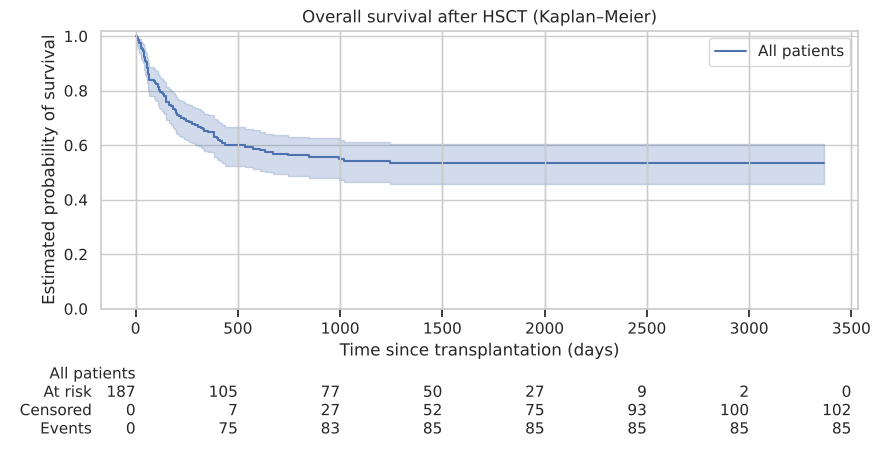

Median overall survival: inf


,S(t)
365,0.647
730,0.569
1825,0.533


In [6]:
kmf_all = KaplanMeierFitter()
kmf_all.fit(df["survival_time"], df["survival_status"], label="All patients")

fig, ax = plt.subplots(figsize=(9, 5))
kmf_all.plot_survival_function(ax=ax)
add_at_risk_counts(kmf_all, ax=ax)
ax.set_title("Overall survival after HSCT (Kaplan–Meier)")
ax.set_xlabel("Time since transplantation (days)")
ax.set_ylabel("Estimated probability of survival")
ax.set_ylim(0, 1.02)
plt.tight_layout()
plt.show()

print("Median overall survival:", kmf_all.median_survival_time_)
display(kmf_all.survival_function_at_times([365, 730, 1825]).rename("S(t)").to_frame())

Overall survival falls steeply in the first year, from 100% to about 65% at 1 year, then flattens (≈ 57% at 2 years, ≈ 53% at 5 years). Most deaths are therefore early, transplant-related events. The median survival time is not reached because more than half of the patients are still alive at the end of follow-up.

### 9.2 Survival by stem-cell source

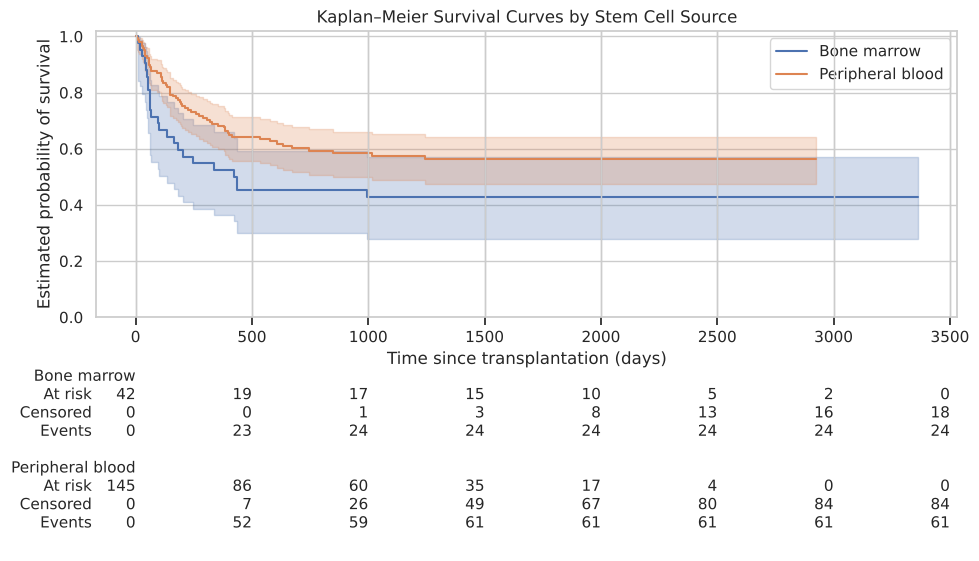

,patients,deaths,S(1 year),S(5 years),median (days)
Bone marrow,42,24,0.524,0.429,421.000
Peripheral blood,145,61,0.683,0.563,inf


In [7]:
bone_marrow = df[df["Stemcellsource"] == "0"]
peripheral_blood = df[df["Stemcellsource"] == "1"]

kmf_bm = KaplanMeierFitter().fit(bone_marrow["survival_time"], bone_marrow["survival_status"], label="Bone marrow")
kmf_pb = KaplanMeierFitter().fit(peripheral_blood["survival_time"], peripheral_blood["survival_status"], label="Peripheral blood")

fig, ax = plt.subplots(figsize=(10, 6))
kmf_bm.plot_survival_function(ax=ax)
kmf_pb.plot_survival_function(ax=ax)
add_at_risk_counts(kmf_bm, kmf_pb, ax=ax)
ax.set_title("Kaplan–Meier Survival Curves by Stem Cell Source")
ax.set_xlabel("Time since transplantation (days)")
ax.set_ylabel("Estimated probability of survival")
ax.set_ylim(0, 1.02)
plt.tight_layout()
plt.show()

km_table = pd.DataFrame({
    "patients": [len(bone_marrow), len(peripheral_blood)],
    "deaths": [int(bone_marrow["survival_status"].sum()), int(peripheral_blood["survival_status"].sum())],
    "S(1 year)": [kmf_bm.predict(365), kmf_pb.predict(365)],
    "S(5 years)": [kmf_bm.predict(1825), kmf_pb.predict(1825)],
    "median (days)": [kmf_bm.median_survival_time_, kmf_pb.median_survival_time_],
}, index=["Bone marrow", "Peripheral blood"])
display(km_table)

In [8]:
results = logrank_test(
    bone_marrow["survival_time"], peripheral_blood["survival_time"],
    event_observed_A=bone_marrow["survival_status"],
    event_observed_B=peripheral_blood["survival_status"],
)
results.print_summary()
print(f"Log-rank test statistic: {results.test_statistic:.4f}")
print(f"Exact p-value: {results.p_value:.8f}")

Log-rank test statistic: 3.8344
Exact p-value: 0.05021141


The Kaplan–Meier curves suggest that PB recipients had higher estimated survival than BM recipients over most of follow-up (1-year survival ≈ 68% vs 52%). The log-rank test gives χ² = 3.83 (1 df), **p = 0.0502**. At α = 0.05 the null hypothesis of equal survival distributions is *not* rejected, although the result is borderline. The difference is mostly early, within the first year. **H1a is not supported at the 5% level.** This is an unadjusted comparison.

## 10. CD34+ cell dose and stem-cell source (new)
The preliminary-study plan (§2.2) required comparing CD34+ dose between the source groups *before* fitting adjusted models: if PB grafts carry much larger doses, part of any PB advantage may run through dose.

,count,mean,std,min,25%,50%,75%,max
Stemcellsource,,,,,,,,
Bone marrow,42.000,4.020,2.510,0.790,1.945,3.425,5.135,10.960
Peripheral blood,145.000,14.172,10.093,0.820,7.870,11.270,17.300,57.780


Mann–Whitney U = 5552, p = 4.87e-16
Median CD34+ dose ratio PB / BM: 3.29
Spearman correlation CD34+ dose vs recipient age: rho = -0.458, p = 4.39e-11


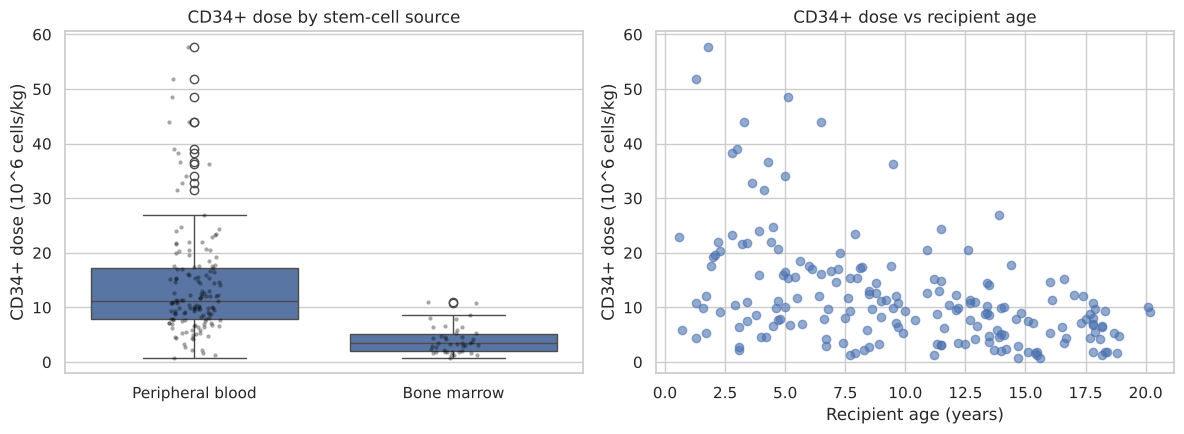

In [9]:
src_label = df["Stemcellsource"].map({"0": "Bone marrow", "1": "Peripheral blood"})

display(df.groupby(src_label)["CD34kgx10d6"].describe())

mw = mannwhitneyu(peripheral_blood["CD34kgx10d6"], bone_marrow["CD34kgx10d6"], alternative="two-sided")
print(f"Mann–Whitney U = {mw.statistic:.0f}, p = {mw.pvalue:.2e}")
ratio = peripheral_blood["CD34kgx10d6"].median() / bone_marrow["CD34kgx10d6"].median()
print(f"Median CD34+ dose ratio PB / BM: {ratio:.2f}")

rho_age, p_age = spearmanr(df["CD34kgx10d6"], df["Recipientage"])
print(f"Spearman correlation CD34+ dose vs recipient age: rho = {rho_age:.3f}, p = {p_age:.2e}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(x=src_label, y=df["CD34kgx10d6"], ax=axes[0])
sns.stripplot(x=src_label, y=df["CD34kgx10d6"], ax=axes[0], color="black", alpha=0.35, size=3)
axes[0].set_xlabel(""); axes[0].set_ylabel("CD34+ dose (10^6 cells/kg)")
axes[0].set_title("CD34+ dose by stem-cell source")
axes[1].scatter(df["Recipientage"], df["CD34kgx10d6"], alpha=0.6)
axes[1].set_xlabel("Recipient age (years)"); axes[1].set_ylabel("CD34+ dose (10^6 cells/kg)")
axes[1].set_title("CD34+ dose vs recipient age")
plt.tight_layout(); plt.show()

PB recipients received a **much higher CD34+ dose**: median 11.3 vs 3.4 ×10⁶/kg, about 3.3 times higher (Mann–Whitney p < 0.001). Dose is also negatively correlated with recipient age (ρ ≈ −0.46), because the dose is expressed *per kg* and younger children weigh less. Source, dose and age are therefore entangled. This is the reason for the nested model sequence below.

## 11. Multivariable Cox proportional-hazards modelling
### 11.1 Candidate variables

In [10]:
candidate_vars = ["Stemcellsource", "CD34kgx10d6", "Recipientage", "Donorage", "Riskgroup", "Disease"]
print("Missing values:")
display(df[candidate_vars].isna().sum())
display(df[["CD34kgx10d6", "Recipientage", "Donorage"]].describe())
for column in ["Stemcellsource", "Riskgroup", "Disease"]:
    print(f"\n{column}:")
    display(df[column].value_counts(dropna=False))

Missing values:


Stemcellsource    0
CD34kgx10d6       0
Recipientage      0
Donorage          0
Riskgroup         0
Disease           0
dtype: int64

,CD34kgx10d6,Recipientage,Donorage
count,187.000,187.000,187.000
mean,11.892,9.932,33.472
std,9.914,5.306,8.272
min,0.790,0.600,18.647
25%,5.350,5.050,27.040
50%,9.720,9.600,33.551
75%,15.415,14.050,40.118
max,57.780,20.200,55.553



Stemcellsource:


Stemcellsource
1    145
0     42
Name: count, dtype: int64


Riskgroup:


Riskgroup
0    118
1     69
Name: count, dtype: int64


Disease:


Disease
ALL             68
chronic         45
AML             33
nonmalignant    32
lymphoma         9
Name: count, dtype: int64

### 11.2 Modelling dataset
Binary variables are converted to integers and `Disease` is dummy-coded with **ALL** as reference. For the quadratic age model, age is **centred at the sample mean** (9.93 years) before squaring. This keeps the linear and squared terms from being nearly collinear, and makes the linear term interpretable as the age effect at the average age.

In [11]:
cox_df = df[["survival_time", "survival_status", "Stemcellsource", "CD34kgx10d6",
             "Recipientage", "Riskgroup", "Disease"]].copy()
cox_df["Stemcellsource"] = cox_df["Stemcellsource"].astype(int)
cox_df["Riskgroup"] = cox_df["Riskgroup"].astype(int)
cox_df = pd.get_dummies(cox_df, columns=["Disease"], drop_first=True, dtype=int)

AGE_MEAN = cox_df["Recipientage"].mean()
cox_df["Recipientage_c"] = cox_df["Recipientage"] - AGE_MEAN
cox_df["Recipientage_c2"] = cox_df["Recipientage_c"] ** 2

disease_dummies = [c for c in cox_df.columns if c.startswith("Disease_")]
OUTCOME = ["survival_time", "survival_status"]

MODEL_SPECS = {
    "Model 1: source": ["Stemcellsource"],
    "Model 2: + CD34+ dose": ["Stemcellsource", "CD34kgx10d6"],
    "Model 3: + age, risk, disease": ["Stemcellsource", "CD34kgx10d6", "Recipientage", "Riskgroup"] + disease_dummies,
    "Model 3q: age centred + age²": ["Stemcellsource", "CD34kgx10d6", "Recipientage_c", "Recipientage_c2", "Riskgroup"] + disease_dummies,
}

def fit_cox(data, predictors):
    model = CoxPHFitter()
    model.fit(data[OUTCOME + predictors], duration_col="survival_time", event_col="survival_status")
    return model

models = {name: fit_cox(cox_df, preds) for name, preds in MODEL_SPECS.items()}
print(f"Mean recipient age used for centring: {AGE_MEAN:.3f} years")

Mean recipient age used for centring: 9.932 years


### 11.3 Nested models: does the source effect change with adjustment? (H1b)

In [12]:
rows = []
for name, m in models.items():
    s = m.summary.loc["Stemcellsource"]
    rows.append({
        "model": name,
        "parameters": len(m.params_),
        "HR source (PB vs BM)": s["exp(coef)"],
        "95% CI lower": s["exp(coef) lower 95%"],
        "95% CI upper": s["exp(coef) upper 95%"],
        "p": s["p"],
        "log-HR (beta)": s["coef"],
        "C-index (in-sample)": m.concordance_index_,
        "partial AIC": m.AIC_partial_,
    })
nested = pd.DataFrame(rows).set_index("model")
beta_m1 = nested.loc["Model 1: source", "log-HR (beta)"]
nested["% change in beta vs Model 1"] = 100 * (nested["log-HR (beta)"] - beta_m1) / abs(beta_m1)
display(nested.round(3))

for name in ["Model 2: + CD34+ dose", "Model 3: + age, risk, disease"]:
    s = models[name].summary.loc["CD34kgx10d6"]
    print(f"{name}: CD34+ HR per 1e6/kg = {s['exp(coef)']:.3f} "
          f"({s['exp(coef) lower 95%']:.3f}–{s['exp(coef) upper 95%']:.3f}), p = {s['p']:.3f}")

cd34_only = fit_cox(cox_df, ["CD34kgx10d6"]).summary.loc["CD34kgx10d6"]
print(f"CD34+ alone (unadjusted): HR = {cd34_only['exp(coef)']:.3f} "
      f"({cd34_only['exp(coef) lower 95%']:.3f}–{cd34_only['exp(coef) upper 95%']:.3f}), p = {cd34_only['p']:.3f}")

,parameters,HR source (PB vs BM),95% CI lower,95% CI upper,p,log-HR (beta),C-index (in-sample),partial AIC,% change in beta vs Model 1
model,,,,,,,,,
Model 1: source,1,0.626,0.390,1.004,0.052,-0.469,0.549,837.996,0.000
Model 2: + CD34+ dose,2,0.778,0.454,1.334,0.362,-0.251,0.595,837.427,46.442
"Model 3: + age, risk, disease",8,0.728,0.416,1.274,0.267,-0.317,0.629,832.414,32.341
Model 3q: age centred + age²,9,0.770,0.442,1.342,0.356,-0.261,0.639,828.234,44.258


Model 2: + CD34+ dose: CD34+ HR per 1e6/kg = 0.978 (0.949–1.007), p = 0.133
Model 3: + age, risk, disease: CD34+ HR per 1e6/kg = 0.990 (0.959–1.023), p = 0.565
CD34+ alone (unadjusted): HR = 0.971 (0.945–0.998), p = 0.035


**Bootstrap test of attenuation (H1b).** We resample patients with replacement 1,000 times, refit Models 1 and 2 on each resample, and record the difference β<sub>M1</sub> − β<sub>M2</sub>. The percentile 95% CI tells us whether the attenuation exceeds what sampling noise alone would produce.

In [13]:
rng = np.random.default_rng(RANDOM_STATE)
N_BOOT = 1000
diffs, pct = [], []
warnings.filterwarnings("ignore")
for _ in range(N_BOOT):
    sample = cox_df.iloc[rng.integers(0, len(cox_df), len(cox_df))]
    try:
        b1 = fit_cox(sample, MODEL_SPECS["Model 1: source"]).params_["Stemcellsource"]
        b2 = fit_cox(sample, MODEL_SPECS["Model 2: + CD34+ dose"]).params_["Stemcellsource"]
    except Exception:
        continue
    diffs.append(b1 - b2)
    pct.append(100 * (b2 - b1) / abs(b1))
diffs = np.array(diffs)

b1 = models["Model 1: source"].params_["Stemcellsource"]
b2 = models["Model 2: + CD34+ dose"].params_["Stemcellsource"]
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"Successful bootstrap resamples: {len(diffs)}")
print(f"beta Model 1 = {b1:.4f} (HR {np.exp(b1):.3f}); beta Model 2 = {b2:.4f} (HR {np.exp(b2):.3f})")
print(f"Observed attenuation: {100 * (b1 - b2) / b1:.1f}% of the Model-1 log-HR moved towards 0")
print(f"Difference beta_M1 - beta_M2 = {b1 - b2:.4f}, bootstrap 95% CI [{lo:.4f}, {hi:.4f}]")
print(f"Share of resamples with attenuation (diff < 0 means beta moved toward 0): {(diffs < 0).mean():.3f}")

Successful bootstrap resamples: 1000
beta Model 1 = -0.4686 (HR 0.626); beta Model 2 = -0.2510 (HR 0.778)
Observed attenuation: 46.4% of the Model-1 log-HR moved towards 0
Difference beta_M1 - beta_M2 = -0.2176, bootstrap 95% CI [-0.5502, 0.0746]
Share of resamples with attenuation (diff < 0 means beta moved toward 0): 0.939


**Interpretation.**
- *Model 1 (source only):* HR 0.63 (0.39–1.00), p = 0.052. This is the Cox counterpart of the borderline log-rank result.
- *Model 2 (+ CD34+ dose):* HR 0.78 (0.45–1.33), p = 0.36. The log-HR for source moves **≈ 46% closer to zero**, so part of the apparent PB advantage is shared with the higher CD34+ dose that PB grafts deliver.
- *Model 3 / 3q (+ age, risk group, disease):* HR 0.73–0.77 (32–44% attenuation), still not significant.

**H1b decision.** The point estimate easily meets the ≥ 10% change-in-estimate criterion, and attenuation occurs in about 94% of bootstrap resamples. However, the bootstrap 95% CI for β<sub>M1</sub> − β<sub>M2</sub> (≈ −0.55 to 0.07) **includes 0**. By our pre-specified rule, **H1b is not formally supported**: the direction is consistent with the hypothesis, but with 42 BM patients the data cannot separate the attenuation from sampling noise. Because the unadjusted association was itself borderline (H1a, p ≈ 0.05), H1 overall is **not supported**.

CD34+ dose on its own is associated with lower hazard (HR 0.971 per 10⁶/kg, p = 0.035). The association weakens once source is added (p = 0.13) and disappears after adjusting for age and disease (Model 3, p = 0.57), consistent with dose being partly a proxy for the child's age and body size.

### 11.4 Detailed results of the adjusted Cox model with linear age (Model 3)

In [14]:
cph = models["Model 3: + age, risk, disease"]
cph.print_summary()

<lifelines.CoxPHFitter: fitted with 187 total observations, 102 right-censored observations>
             duration col = 'survival_time'
                event col = 'survival_status'
      baseline estimation = breslow
   number of observations = 187
number of events observed = 85
   partial log-likelihood = -408.21
         time fit was run = 2026-10-24 23:48:14 UTC

---
                      coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                             
Stemcellsource       -0.32      0.73      0.29           -0.88            0.24                0.42                1.27
CD34kgx10d6          -0.01      0.99      0.02           -0.04            0.02                0.96                1.02
Recipientage          0.06      1.06      0.03            0.01            0.11                1.01                1.12
Riskgroup             0.20      1.22      0.25           -0.29            0.69                0.74                1.99
Disease_AML          -0.23      0.79      0.36           -0.93            0.46                0.40                1.59
Disease_chronic      -0.12      0.89      0.30           -0.72            0.47                0.49                1.60
Disease_lymphoma      1.15      3.17      0.43            0.31            2.00                1.36                7.39
Disease_nonmalignant  0.12      1.13      0.36           -0.58            0.83                0.56                2.28

                      cmp to     z    p  -log2(p)
covariate                                        
Stemcellsource          0.00 -1.11 0.27      1.91
CD34kgx10d6             0.00 -0.58 0.56      0.82
Recipientage            0.00  2.19 0.03      5.14
Riskgroup               0.00  0.79 0.43      1.21
Disease_AML             0.00 -0.65 0.51      0.96
Disease_chronic         0.00 -0.40 0.69      0.54
Disease_lymphoma        0.00  2.67 0.01      7.04
Disease_nonmalignant    0.00  0.34 0.73      0.45
---
Concordance = 0.63
Partial AIC = 832.41
log-likelihood ratio test = 23.09 on 8 df
-log2(p) of ll-ratio test = 8.26

**Stem-cell source (primary variable).** Adjusted HR 0.73 (95% CI 0.42–1.27, p = 0.27): an estimated 27% lower instantaneous hazard of death for PB recipients, conditional on the other predictors. The CI includes 1, so there is no sufficient evidence of an adjusted association at the 5% level.

**CD34+ cell dose.** HR 0.99 per 10⁶ cells/kg (p = 0.56). **H2 is not supported.**

**Recipient age.** HR 1.06 per year (p = 0.03): older age is associated with higher hazard under a linear specification. The functional form is examined in §11.6.

**Disease category.** Lymphoma vs ALL: HR 3.17 (p = 0.008), an imprecise estimate (see the event table below).

In [15]:
cph.check_assumptions(cox_df[OUTCOME + MODEL_SPECS["Model 3: + age, risk, disease"]],
                      p_value_threshold=0.05, show_plots=False)

Proportional hazard assumption looks okay.


[]

**Proportional hazards.** Schoenfeld-residual tests found no variable with p < 0.05, so there is no statistically significant evidence of time-varying effects. This supports, but does not prove, the PH assumption.

In [16]:
disease_events = df.groupby("Disease", observed=False)["survival_status"].agg(patients="count", deaths="sum")
disease_events["alive_at_last_observation"] = disease_events["patients"] - disease_events["deaths"]
display(disease_events)

,patients,deaths,alive_at_last_observation
Disease,,,
ALL,68,30.000,38.000
AML,33,15.000,18.000
chronic,45,19.000,26.000
lymphoma,9,9.000,0.000
nonmalignant,32,12.000,20.000


All 9 lymphoma patients died during follow-up. With so few patients the lymphoma HR is unstable, so a sensitivity analysis excluding them is run in §11.8.

### 11.5 Functional form of the continuous predictors

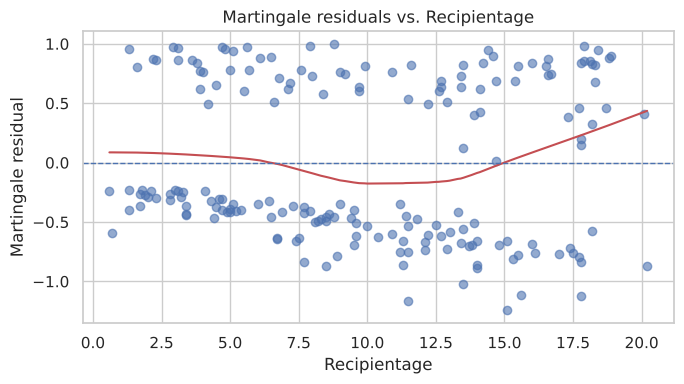

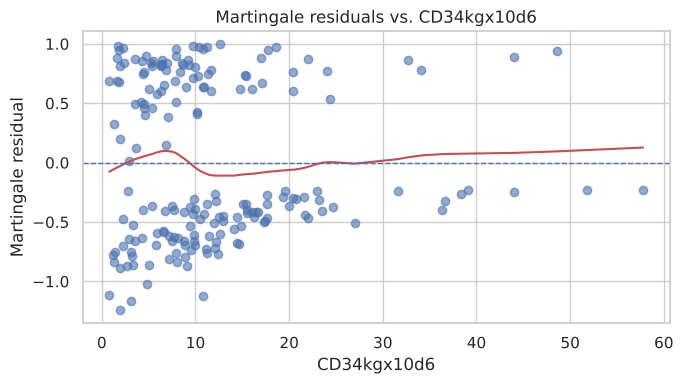

In [17]:
from statsmodels.nonparametric.smoothers_lowess import lowess

martingale_residuals = cph.compute_residuals(cox_df[OUTCOME + MODEL_SPECS["Model 3: + age, risk, disease"]], kind="martingale")
for variable in ["Recipientage", "CD34kgx10d6"]:
    x = cox_df.loc[martingale_residuals.index, variable]
    y = martingale_residuals["martingale"]
    smoothed = lowess(y, x, frac=0.6, return_sorted=True)
    plt.figure(figsize=(7, 4))
    plt.scatter(x, y, alpha=0.6)
    plt.plot(smoothed[:, 0], smoothed[:, 1], color="C3")
    plt.axhline(0, linestyle="--", linewidth=1)
    plt.xlabel(variable); plt.ylabel("Martingale residual")
    plt.title(f"Martingale residuals vs. {variable}")
    plt.tight_layout(); plt.show()

**Recipient age:** the smoothed line declines through the middle age range and rises again at older ages, which suggests possible non-linearity. **CD34+ dose:** the line stays close to zero, roughly linear, with sparse data at high doses. These plots are exploratory, so a formal comparison follows.

### 11.6 Quadratic age term (Model 3q)

In [18]:
cph_age_nonlinear = models["Model 3q: age centred + age²"]

lr_statistic = 2 * (cph_age_nonlinear.log_likelihood_ - cph.log_likelihood_)
lr_p_value = chi2.sf(lr_statistic, df=1)
print(f"Likelihood-ratio statistic: {lr_statistic:.4f}")
print(f"p-value: {lr_p_value:.4f}")

final_results = cph_age_nonlinear.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].copy()
final_results.columns = ["Hazard Ratio", "95% CI Lower", "95% CI Upper", "p-value"]
display(final_results.round(3))

b_lin = cph_age_nonlinear.params_["Recipientage_c"]
b_sq = cph_age_nonlinear.params_["Recipientage_c2"]
age_lowest_risk = AGE_MEAN - b_lin / (2 * b_sq)
print(f"Age with the lowest estimated hazard: {age_lowest_risk:.1f} years")

Likelihood-ratio statistic: 6.1802
p-value: 0.0129


,Hazard Ratio,95% CI Lower,95% CI Upper,p-value
covariate,,,,
Stemcellsource,0.770,0.442,1.342,0.356
CD34kgx10d6,0.984,0.952,1.016,0.321
Recipientage_c,1.050,0.999,1.102,0.053
Recipientage_c2,1.011,1.003,1.020,0.010
Riskgroup,1.169,0.712,1.919,0.538
Disease_AML,0.682,0.335,1.385,0.289
Disease_chronic,0.899,0.497,1.629,0.727
Disease_lymphoma,4.203,1.743,10.133,0.001
Disease_nonmalignant,1.159,0.573,2.347,0.681


Age with the lowest estimated hazard: 7.7 years


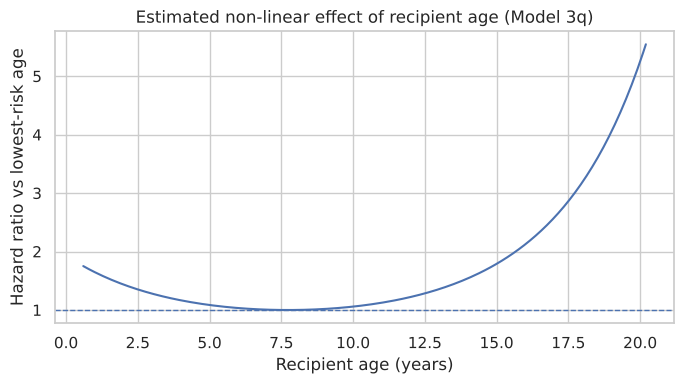

In [19]:
# Partial effect of age: HR relative to the age with lowest hazard
ages = np.linspace(cox_df["Recipientage"].min(), cox_df["Recipientage"].max(), 200)
ac = ages - AGE_MEAN
log_hr = b_lin * ac + b_sq * ac**2
log_hr -= log_hr.min()

plt.figure(figsize=(7, 4))
plt.plot(ages, np.exp(log_hr))
plt.axhline(1, linestyle="--", linewidth=1)
plt.xlabel("Recipient age (years)")
plt.ylabel("Hazard ratio vs lowest-risk age")
plt.title("Estimated non-linear effect of recipient age (Model 3q)")
plt.tight_layout(); plt.show()

**Proportional hazards for the final model.** The global Schoenfeld test table:

In [20]:
ph_final = proportional_hazard_test(
    cph_age_nonlinear, cox_df[OUTCOME + MODEL_SPECS["Model 3q: age centred + age²"]], time_transform="rank"
)
display(ph_final.summary.round(3))

,test_statistic,p,-log2(p)
CD34kgx10d6,0.066,0.798,0.326
Disease_AML,0.008,0.927,0.109
Disease_chronic,0.273,0.601,0.734
Disease_lymphoma,0.033,0.855,0.226
Disease_nonmalignant,2.361,0.124,3.007
Recipientage_c,0.079,0.779,0.360
Recipientage_c2,3.461,0.063,3.992
Riskgroup,1.561,0.211,2.241
Stemcellsource,1.138,0.286,1.806


**Results of the quadratic Cox model.** Adding age² improved fit (LR = 6.18, 1 df, p = 0.013). Age has a **U-shaped** association with hazard: risk is lowest around 7–8 years and higher in infants and adolescents. Because age is now centred, the linear term (HR 1.05, p = 0.053) is the age slope at the mean age of 9.9 years. In V2 it was the slope at age 0. All other coefficients, the likelihood, AIC and C-index are identical to V2.

Stem-cell source: HR 0.77 (0.44–1.34, p = 0.36). CD34+ dose: HR 0.984 (0.952–1.016, p = 0.32). Lymphoma vs ALL: HR 4.20 (1.74–10.13, p = 0.001). No PH test reached p < 0.05; age² was the closest (p ≈ 0.06), so its effect may vary somewhat over time.

**Caveat.** The quadratic term was added *after* inspecting the residual plots, so the LR p-value is somewhat optimistic.

### 11.7 Model comparison

In [21]:
model_comparison = pd.DataFrame({
    "Model": ["Linear age (Model 3)", "Quadratic age (Model 3q)"],
    "Partial AIC": [cph.AIC_partial_, cph_age_nonlinear.AIC_partial_],
    "Concordance index (in-sample)": [cph.concordance_index_, cph_age_nonlinear.concordance_index_],
    "Log-likelihood": [cph.log_likelihood_, cph_age_nonlinear.log_likelihood_],
    "Number of parameters": [len(cph.params_), len(cph_age_nonlinear.params_)],
    "Events per parameter": [85 / len(cph.params_), 85 / len(cph_age_nonlinear.params_)],
})
display(model_comparison.round(3))

,Model,Partial AIC,Concordance index (in-sample),Log-likelihood,Number of parameters,Events per parameter
0,Linear age (Model 3),832.414,0.629,-408.207,8,10.625
1,Quadratic age (Model 3q),828.234,0.639,-405.117,9,9.444


The quadratic model has a lower AIC (Δ = 4.2) and a slightly higher in-sample C-index (0.639 vs 0.629). With 9 parameters for 85 deaths (≈ 9.4 events per parameter), the model is at the usual limit of complexity for this sample size, so no further covariates are added.

### 11.8 Sensitivity analyses (new)

In [22]:
sens = {}
sens["Main (Model 3q)"] = cph_age_nonlinear

# (a) exclude the 9 lymphoma patients
no_lym = cox_df[cox_df["Disease_lymphoma"] == 0]
preds_a = [p for p in MODEL_SPECS["Model 3q: age centred + age²"] if p != "Disease_lymphoma"]
sens["Excluding lymphoma (n=178)"] = fit_cox(no_lym, preds_a)

# (b) log-transformed CD34+ dose (right-skewed)
cox_df["log_CD34"] = np.log(cox_df["CD34kgx10d6"])
preds_b = [("log_CD34" if p == "CD34kgx10d6" else p) for p in MODEL_SPECS["Model 3q: age centred + age²"]]
sens["log(CD34+) instead of CD34+"] = fit_cox(cox_df, preds_b)

# (c) stratify by disease instead of disease dummies
strat_df = cox_df[OUTCOME + ["Stemcellsource", "CD34kgx10d6", "Recipientage_c", "Recipientage_c2", "Riskgroup"]].copy()
strat_df["Disease"] = df["Disease"].values
m_strat = CoxPHFitter().fit(strat_df, "survival_time", "survival_status", strata=["Disease"])
sens["Stratified by disease"] = m_strat

rows = []
for name, m in sens.items():
    s = m.summary.loc["Stemcellsource"]
    cd = "log_CD34" if "log_CD34" in m.params_.index else "CD34kgx10d6"
    c = m.summary.loc[cd]
    rows.append({"analysis": name,
                 "HR source": s["exp(coef)"], "source CI": f"{s['exp(coef) lower 95%']:.2f}–{s['exp(coef) upper 95%']:.2f}", "p source": s["p"],
                 "HR CD34+ term": c["exp(coef)"], "p CD34+": c["p"]})
display(pd.DataFrame(rows).set_index("analysis").round(3))

,HR source,source CI,p source,HR CD34+ term,p CD34+
analysis,,,,,
Main (Model 3q),0.770,0.44–1.34,0.356,0.984,0.321
Excluding lymphoma (n=178),0.702,0.39–1.26,0.233,0.987,0.476
log(CD34+) instead of CD34+,0.822,0.43–1.58,0.555,0.838,0.348
Stratified by disease,0.795,0.46–1.39,0.420,0.977,0.184


The conclusions hold in every sensitivity analysis. Source HRs stay between 0.70 and 0.82, all non-significant. The CD34+ dose term remains non-significant whether it is entered linearly or log-transformed, and whether disease is adjusted for or stratified. The source and dose findings are therefore not driven by the small lymphoma group or by the scale of the dose variable.

### 11.9 Hypothesis decisions

In [23]:
decisions = pd.DataFrame([
    ["H1a", "Source associated with OS (unadjusted)", "Log-rank χ²(1)",
     f"χ² = {results.test_statistic:.2f}, p = {results.p_value:.3f}", "Not supported at α = 0.05 (borderline)"],
    ["H1b", "Source association weakens after CD34+ adjustment", "Change in β, bootstrap CI",
     f"{100*(b1-b2)/b1:.0f}% attenuation; diff CI [{lo:.2f}, {hi:.2f}]",
     "Supported" if (abs(100*(b1-b2)/b1) >= 10 and (lo > 0 or hi < 0)) else "Not supported (right direction, CI includes 0)"],
    ["H2", "Higher CD34+ dose → longer OS (adjusted)", "Wald z, Model 3",
     f"HR = {cph.summary.loc['CD34kgx10d6','exp(coef)']:.3f}, p = {cph.summary.loc['CD34kgx10d6','p']:.3f}", "Not supported"],
], columns=["", "Hypothesis", "Test", "Result", "Decision"]).set_index("")
display(decisions)

,Hypothesis,Test,Result,Decision
,,,,
H1a,Source associated with OS (unadjusted),Log-rank χ²(1),"χ² = 3.83, p = 0.050",Not supported at α = 0.05 (borderline)
H1b,Source association weakens after CD34+ adjustment,"Change in β, bootstrap CI","46% attenuation; diff CI [-0.55, 0.07]","Not supported (right direction, CI includes 0)"
H2,Higher CD34+ dose → longer OS (adjusted),"Wald z, Model 3","HR = 0.990, p = 0.565",Not supported


## 12. Machine-learning survival analysis: Random Survival Forest (new)
A Random Survival Forest (RSF; Ishwaran et al., 2008) grows many survival trees on bootstrap samples and averages their cumulative hazard estimates. It can capture non-linearities and interactions without specifying them, but it can overfit on small samples.

**Design choices to limit overfitting (n = 187):**
- **Pre-transplant features only.** Post-transplant variables are excluded (relapse, acute/chronic GvHD, recovery times, `IIIV`), as are dichotomised duplicates (`Donorage35`, `Recipientage10`, `Recipientageint`, `Diseasegroup`, `HLAmismatch`).
- **Hyper-parameters fixed a priori, not tuned:** 500 trees, `min_samples_leaf = 10`, `max_features = "sqrt"`. Tuning on 187 patients would require nested CV and would add optimism.
- **Evaluation by 5 × repeated stratified 5-fold cross-validation**, with imputation fitted inside each training fold.
- **Survival-specific metrics:** Harrell's C-index on held-out folds, and the integrated Brier score (IBS) over days 30–1,500. Lower IBS is better; a non-informative model scores ≈ 0.25.
- **Benchmarks:** the same pipeline with a Cox model on the 9 Model-3q variables, and on all pre-transplant features (ridge-penalised).

In [24]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.inspection import permutation_importance
from sksurv.ensemble import RandomSurvivalForest
from sksurv.linear_model import CoxPHSurvivalAnalysis
from sksurv.metrics import concordance_index_censored, integrated_brier_score
from sksurv.util import Surv

numeric_features = ["Recipientage", "Donorage", "CD34kgx10d6", "CD3dCD34", "CD3dkgx10d8", "Rbodymass",
                    "CMVstatus", "HLAmatch", "Antigen", "Alel", "HLAgrI"]
binary_features = ["Recipientgender", "Stemcellsource", "Gendermatch", "RecipientRh", "ABOmatch",
                   "DonorCMV", "RecipientCMV", "Riskgroup", "Txpostrelapse"]
nominal_features = ["Disease", "DonorABO", "RecipientABO"]

X = df[numeric_features + binary_features + nominal_features].copy()
for c in numeric_features + binary_features:
    X[c] = pd.to_numeric(X[c])
y = Surv.from_arrays(event=df["survival_status"].astype(bool), time=df["survival_time"])

print("Feature matrix:", X.shape)
print("Missing values per feature (imputed inside the pipeline):")
display(X.isna().sum()[X.isna().sum() > 0])

preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("bin", SimpleImputer(strategy="most_frequent"), binary_features),
    ("nom", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), nominal_features),
])

Feature matrix: (187, 23)
Missing values per feature (imputed inside the pipeline):


CD3dCD34         5
CD3dkgx10d8      5
Rbodymass        2
CMVstatus       16
Antigen          1
Alel             1
RecipientRh      2
ABOmatch         1
DonorCMV         2
RecipientCMV    14
RecipientABO     1
dtype: int64

In [25]:
cox9_features = ["Stemcellsource", "CD34kgx10d6", "Recipientage", "Riskgroup", "Disease"]

def make_cox9_X(frame):
    """Model-3q design: source, CD34+, centred age + age², risk group, disease dummies (ALL reference)."""
    out = frame[["Stemcellsource", "CD34kgx10d6", "Recipientage", "Riskgroup"]].astype(float).copy()
    out["age_c"] = out["Recipientage"] - AGE_MEAN
    out["age_c2"] = out["age_c"] ** 2
    out = out.drop(columns="Recipientage")
    for d in ["AML", "chronic", "lymphoma", "nonmalignant"]:
        out[f"Disease_{d}"] = (frame["Disease"] == d).astype(float)
    return out

X_cox9 = make_cox9_X(df.assign(Stemcellsource=df["Stemcellsource"].astype(int), Riskgroup=df["Riskgroup"].astype(int)))

pipelines = {
    "Random Survival Forest": (Pipeline([("prep", preprocess),
        ("model", RandomSurvivalForest(n_estimators=500, min_samples_leaf=10, max_features="sqrt",
                                       n_jobs=-1, random_state=RANDOM_STATE))]), X),
    "Cox, all features (ridge)": (Pipeline([("prep", preprocess), ("scale", StandardScaler()),
        ("model", CoxPHSurvivalAnalysis(alpha=1.0))]), X),
    "Cox, Model-3q variables": (Pipeline([("model", CoxPHSurvivalAnalysis(alpha=1e-4))]), X_cox9),
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
strata = df["survival_status"].astype(int).values
eval_times_all = np.arange(30, 1501, 30)

cv_records = []
perm_records = []
for fold, (tr, te) in enumerate(cv.split(X, strata)):
    for name, (pipe, Xmat) in pipelines.items():
        Xtr, Xte = Xmat.iloc[tr], Xmat.iloc[te]
        pipe.fit(Xtr, y[tr])
        risk_te = pipe.predict(Xte)
        risk_tr = pipe.predict(Xtr)
        c_te = concordance_index_censored(y[te]["event"], y[te]["time"], risk_te)[0]
        c_tr = concordance_index_censored(y[tr]["event"], y[tr]["time"], risk_tr)[0]
        # IBS: evaluation times must lie inside the follow-up range of the test fold
        t_max = min(y[te]["time"].max(), y[tr]["time"].max())
        times = eval_times_all[(eval_times_all >= y[te]["time"].min()) & (eval_times_all < t_max)]
        surv_fns = pipe.predict_survival_function(Xte)
        preds = np.asarray([[fn(t) for t in times] for fn in surv_fns])
        ibs = integrated_brier_score(y[tr], y[te], preds, times)
        cv_records.append({"fold": fold, "model": name, "C-index test": c_te, "C-index train": c_tr, "IBS test": ibs})

        if name == "Random Survival Forest":
            pi = permutation_importance(pipe, Xte, y[te], n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
            perm_records.append(pd.Series(pi.importances_mean, index=Xte.columns))

cv_results = pd.DataFrame(cv_records)
summary_cv = cv_results.groupby("model").agg(
    C_test_mean=("C-index test", "mean"), C_test_sd=("C-index test", "std"),
    C_train_mean=("C-index train", "mean"),
    IBS_mean=("IBS test", "mean"), IBS_sd=("IBS test", "std"),
)
summary_cv["optimism (train − test C)"] = summary_cv["C_train_mean"] - summary_cv["C_test_mean"]
display(summary_cv.round(3))

,C_test_mean,C_test_sd,C_train_mean,IBS_mean,IBS_sd,optimism (train − test C)
model,,,,,,
"Cox, Model-3q variables",0.592,0.074,0.648,0.230,0.025,0.056
"Cox, all features (ridge)",0.524,0.075,0.700,0.292,0.044,0.176
Random Survival Forest,0.573,0.069,0.757,0.234,0.019,0.184


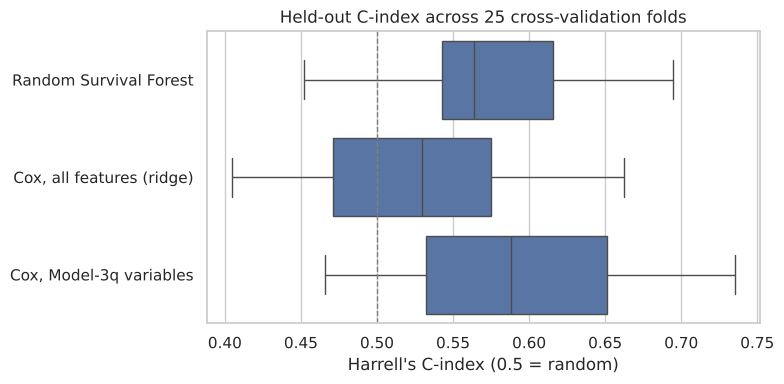

In [26]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=cv_results, x="C-index test", y="model", ax=ax)
ax.axvline(0.5, linestyle="--", color="grey", linewidth=1)
ax.set_title("Held-out C-index across 25 cross-validation folds")
ax.set_xlabel("Harrell's C-index (0.5 = random)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

,mean drop in C-index,sd,share of folds > 0
Recipientage,0.025,0.026,0.880
CD34kgx10d6,0.013,0.015,0.840
Rbodymass,0.011,0.016,0.800
Donorage,0.006,0.015,0.680
Riskgroup,0.006,0.006,0.880
RecipientRh,0.003,0.004,0.840
Stemcellsource,0.002,0.005,0.720
CD3dkgx10d8,0.002,0.013,0.680
RecipientCMV,0.001,0.006,0.680
Txpostrelapse,0.000,0.002,0.440


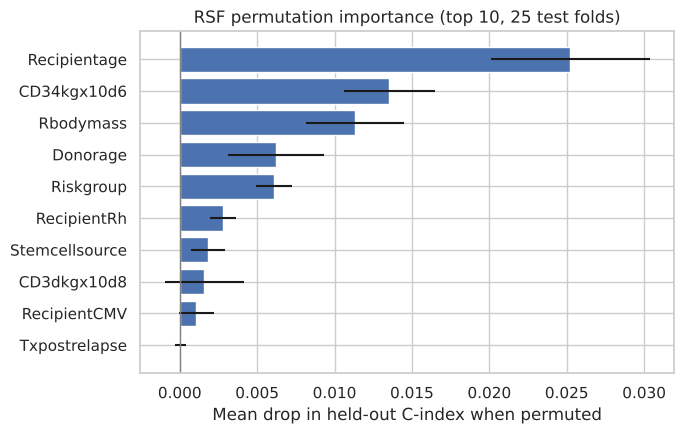

In [27]:
importance = pd.concat(perm_records, axis=1)
imp_summary = pd.DataFrame({"mean drop in C-index": importance.mean(axis=1),
                            "sd": importance.std(axis=1),
                            "share of folds > 0": (importance > 0).mean(axis=1)}).sort_values("mean drop in C-index", ascending=False)
display(imp_summary.round(4))

top = imp_summary.head(10).iloc[::-1]
plt.figure(figsize=(7, 4.5))
plt.barh(top.index, top["mean drop in C-index"], xerr=top["sd"] / np.sqrt(importance.shape[1]))
plt.axvline(0, color="grey", linewidth=1)
plt.xlabel("Mean drop in held-out C-index when permuted")
plt.title("RSF permutation importance (top 10, 25 test folds)")
plt.tight_layout(); plt.show()

**Interpretation.**
- Discrimination on unseen patients is **modest** for every model. The 9-variable Cox model is best (held-out C ≈ 0.59, IBS ≈ 0.23), the RSF slightly lower (C ≈ 0.57, IBS ≈ 0.23), and the ridge Cox model with all 23 features is close to random (C ≈ 0.52; IBS ≈ 0.29, worse than a non-informative 0.25). Baseline characteristics explain only a small part of who survives.
- **Overfitting is visible:** the RSF scores C ≈ 0.76 on its training folds but ≈ 0.57 on held-out folds (optimism ≈ 0.18), and the all-feature Cox model shows a similar gap. The 9-variable Cox model has the smallest gap (≈ 0.06). Adding features hurt rather than helped.
- The RSF therefore does **not** beat the parsimonious Cox model, which remains the primary analysis.
- **Permutation importance** (held-out folds) ranks **recipient age** first, then **CD34+ dose** and **body mass**. These three are strongly correlated (dose is per kg of body weight). Stem-cell source adds little once they are known. Disease contributes nothing in the forest, because the only high-risk group (lymphoma, n = 9) is too small for trees with ≥ 10 patients per leaf to isolate.
- CD34+ dose ranks high in the RSF but is non-significant in the adjusted Cox model. These answer different questions: importance measures *predictive usefulness*, which dose gets partly as a proxy for the child's age and size, whereas the Cox coefficient measures an *independent* association. This difference is itself informative.

These ML results are exploratory and do not change the hypothesis decisions.

## 13. Secondary outcome: engraftment (new)
Time to neutrophil recovery (ANC > 0.5×10⁹/L) and platelet recovery (> 50,000/mm³).

**Handling of placeholders and competing risks.** A patient without recovery (`1,000,000`) either died first or was censored. §7.1 showed that *all* non-recovered patients died. Treating these deaths as ordinary censoring would overstate the probability of recovery, so we use:
- the **Aalen–Johansen** estimator for the *cumulative incidence* of recovery, with death before recovery as a competing event;
- **cause-specific Cox models** (death treated as censoring for the recovery hazard), which estimate how fast recovery happens among patients still alive and un-engrafted;
- the two impossible platelet records (recovery recorded after death) as "no recovery before death".

In [28]:
def engraftment_data(var):
    t_rec = df[var]
    recovered = (t_rec < SENTINEL) & (t_rec <= df["survival_time"])
    time = np.where(recovered, t_rec, df["survival_time"])
    # event codes: 1 = recovery, 2 = death before recovery, 0 = censored alive without recovery
    event = np.where(recovered, 1, np.where(df["survival_status"] == 1, 2, 0))
    out = pd.DataFrame({"time": time, "event": event,
                        "Stemcellsource": df["Stemcellsource"].astype(int),
                        "CD34kgx10d6": df["CD34kgx10d6"], "log_CD34": np.log(df["CD34kgx10d6"]),
                        "Recipientage": df["Recipientage"]})
    return out

eng = {"Neutrophil (ANC) recovery": engraftment_data("ANCrecovery"),
       "Platelet recovery": engraftment_data("PLTrecovery")}

for name, d in eng.items():
    print(name, "— event counts (1 = recovery, 2 = death first, 0 = censored):", d["event"].value_counts().sort_index().to_dict())
    rec = d[d["event"] == 1]
    print("   median days to recovery:", rec.groupby("Stemcellsource")["time"].median().rename({0: "BM", 1: "PB"}).to_dict())

Neutrophil (ANC) recovery — event counts (1 = recovery, 2 = death first, 0 = censored): {1: 182, 2: 5}
   median days to recovery: {'BM': 18.0, 'PB': 14.0}
Platelet recovery — event counts (1 = recovery, 2 = death first, 0 = censored): {1: 168, 2: 19}
   median days to recovery: {'BM': 29.0, 'PB': 18.0}


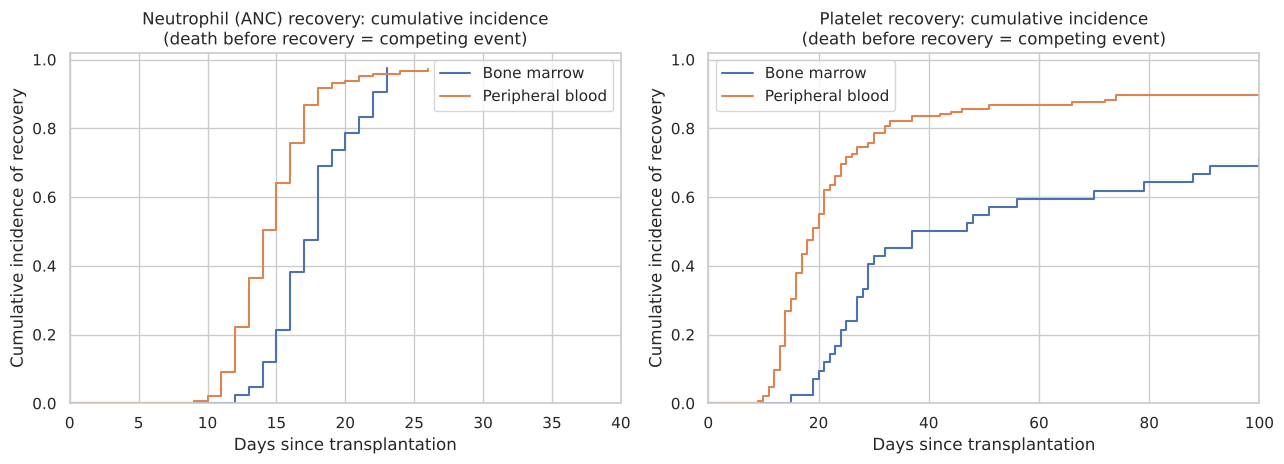

source                         Bone marrow  Peripheral blood
outcome                   day                               
Neutrophil (ANC) recovery 14         0.119             0.421
                          21         0.833             0.952
                          28         0.976             0.972
Platelet recovery         21         0.119             0.607
                          30         0.405             0.786
                          60         0.595             0.869

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
cif_rows = []
for ax, (name, d) in zip(axes, eng.items()):
    horizon = 40 if "ANC" in name else 100
    for s, lab in [(0, "Bone marrow"), (1, "Peripheral blood")]:
        sub = d[d["Stemcellsource"] == s]
        ajf = AalenJohansenFitter(calculate_variance=False, seed=RANDOM_STATE)
        ajf.fit(sub["time"], sub["event"], event_of_interest=1, label=lab)
        ajf.plot(ax=ax)
        cif = ajf.cumulative_density_
        for t in ([14, 21, 28] if "ANC" in name else [21, 30, 60]):
            cif_rows.append({"outcome": name, "source": lab, "day": t,
                             "cumulative incidence": cif.loc[cif.index <= t].iloc[-1, 0]})
    ax.set_xlim(0, horizon); ax.set_ylim(0, 1.02)
    ax.set_title(f"{name}: cumulative incidence\n(death before recovery = competing event)")
    ax.set_xlabel("Days since transplantation"); ax.set_ylabel("Cumulative incidence of recovery")
plt.tight_layout(); plt.show()
display(pd.DataFrame(cif_rows).pivot_table(index=["outcome", "day"], columns="source", values="cumulative incidence").round(3))

In [30]:
eng_rows = []
for name, d in eng.items():
    cs = d.copy()
    cs["recovered"] = (cs["event"] == 1).astype(int)   # cause-specific: competing death -> censored
    for label, preds in [("source only", ["Stemcellsource"]),
                         ("source + log CD34+ + age", ["Stemcellsource", "log_CD34", "Recipientage"])]:
        m = CoxPHFitter().fit(cs[["time", "recovered"] + preds], "time", "recovered")
        for p in preds:
            s = m.summary.loc[p]
            eng_rows.append({"outcome": name, "model": label, "term": p,
                             "cs-HR": s["exp(coef)"], "CI lower": s["exp(coef) lower 95%"],
                             "CI upper": s["exp(coef) upper 95%"], "p": s["p"]})
display(pd.DataFrame(eng_rows).set_index(["outcome", "model", "term"]).round(3))

cs-HR  \
outcome                   model                    term                    
Neutrophil (ANC) recovery source only              Stemcellsource  2.191   
                          source + log CD34+ + age Stemcellsource  1.381   
                                                   log_CD34        1.462   
                                                   Recipientage    0.993   
Platelet recovery         source only              Stemcellsource  2.298   
                          source + log CD34+ + age Stemcellsource  0.980   
                                                   log_CD34        2.294   
                                                   Recipientage    1.026   

                                                                   CI lower  \
outcome                   model                    term                       
Neutrophil (ANC) recovery source only              Stemcellsource     1.534   
                          source + log CD34+ + age Stemcellsource     0.882   
                                                   log_CD34           1.145   
                                                   Recipientage       0.963   
Platelet recovery         source only              Stemcellsource     1.564   
                          source + log CD34+ + age Stemcellsource     0.595   
                                                   log_CD34           1.675   
                                                   Recipientage       0.995   

                                                                   CI upper  \
outcome                   model                    term                       
Neutrophil (ANC) recovery source only              Stemcellsource     3.130   
                          source + log CD34+ + age Stemcellsource     2.162   
                                                   log_CD34           1.867   
                                                   Recipientage       1.023   
Platelet recovery         source only              Stemcellsource     3.378   
                          source + log CD34+ + age Stemcellsource     1.616   
                                                   log_CD34           3.140   
                                                   Recipientage       1.058   

                                                                      p  
outcome                   model                    term                  
Neutrophil (ANC) recovery source only              Stemcellsource 0.000  
                          source + log CD34+ + age Stemcellsource 0.159  
                                                   log_CD34       0.002  
                                                   Recipientage   0.634  
Platelet recovery         source only              Stemcellsource 0.000  
                          source + log CD34+ + age Stemcellsource 0.938  
                                                   log_CD34       0.000  
                                                   Recipientage   0.097

**Interpretation.** For engraftment, HR > 1 means **faster** recovery.
- PB recipients recover faster than BM recipients: median 14 vs 18 days for neutrophils and 18 vs 29 days for platelets. The unadjusted cause-specific HRs are ≈ 2.2 (ANC) and ≈ 2.3 (platelets), both p < 0.001, in line with the preliminary Mann–Whitney results.
- After adding log CD34+ dose and age, **CD34+ dose remains a strong predictor of faster recovery** (ANC cs-HR 1.46 per log-unit, p = 0.002; platelets 2.29, p < 0.001), and the source effect is no longer significant (ANC 1.38, p = 0.16; platelets 0.98, p = 0.94). Dose, not source as such, drives engraftment speed. This is the mediation pattern H1b looked for, and it is clear here, for engraftment, but not for survival.
- Every patient who failed to engraft died. Engraftment is clinically important, but it does not explain the long-term survival differences: most deaths occurred after engraftment, and dose was not associated with survival after adjustment.

## 14. Conclusions

1. **Stem-cell source.** PB recipients had numerically better survival (unadjusted HR 0.63), but the evidence is borderline (log-rank p = 0.050) and disappears after adjustment (HR 0.73–0.78, p > 0.25). **H1a: not supported at α = 0.05.**
2. **Source and dose are entangled.** PB grafts delivered about 3.3× more CD34+ cells/kg. Adding CD34+ dose moved the source log-HR ≈ 46% toward zero, but the bootstrap CI for this change includes 0. **H1b: right direction, not formally supported.**
3. **CD34+ dose and survival.** Dose was associated with survival only before adjustment. After adjusting for age and disease it was not (HR 0.99 per 10⁶/kg, p = 0.57). **H2: not supported.** Dose clearly accelerates *engraftment*, however, and explains the faster engraftment seen with PB grafts.
4. **What does matter:** recipient age (U-shaped; lowest risk around 7–8 years) and lymphoma (a small group with very high mortality).
5. **Prediction:** held-out C-index ≈ 0.59 for the 9-variable Cox model and ≈ 0.57 for the RSF. The RSF overfits (training C ≈ 0.76) and does not beat the simple Cox model.

## 15. Limitations
- Small sample (187 patients, 85 deaths) limits power: a true HR of 0.75 would often go undetected. Non-significance is not evidence of no effect.
- Observational data: stem-cell source was not randomised and may reflect clinician choices linked to unmeasured factors (centre, era, urgency).
- Small subgroups (lymphoma n = 9; BM n = 42) give imprecise estimates.
- The quadratic age term was chosen after inspecting residuals (data-driven).
- Cause of death and post-transplant events (relapse, GvHD) are not modelled as time-dependent covariates; they were deliberately excluded as baseline predictors.
- No external validation cohort; cross-validation estimates internal performance only.

## References
1. Sikora, M., & Wróbel, Ł. *Bone Marrow Transplant: Children* dataset. UCI Machine Learning Repository.
2. Kaplan, E. L., & Meier, P. (1958). Nonparametric estimation from incomplete observations. *JASA*, 53(282), 457–481.
3. Cox, D. R. (1972). Regression models and life-tables. *JRSS B*, 34(2), 187–220.
4. Ishwaran, H., Kogalur, U. B., Blackstone, E. H., & Lauer, M. S. (2008). Random survival forests. *Annals of Applied Statistics*, 2(3), 841–860.
5. Aalen, O. O., & Johansen, S. (1978). An empirical transition matrix for non-homogeneous Markov chains based on censored observations. *Scandinavian Journal of Statistics*, 5(3), 141–150.